# Création d'Images pour Article

Ce notebook permet de charger une vidéo, extraire des frames spécifiques et les afficher côte à côte pour créer des figures d'article.

## Import Required Libraries

Import des bibliothèques nécessaires pour le traitement vidéo et la manipulation d'images.

In [47]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.animation import FFMpegWriter
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import os
from typing import List, Tuple
import subprocess
import json

print("Bibliothèques importées avec succès!")

Bibliothèques importées avec succès!


## Load Video File

Chargement de la vidéo et récupération des propriétés de base.

In [48]:
# Spécifiez le chemin vers votre vidéo
video_path = "../experiments_debug/test_properties_01_01/traj_bridges/traj_iter_6_tpairs_[0.0, 2.0]_direction_forward.mp4"  # Modifiez ce chemin

def load_video_info(video_path: str) -> dict:
    """
    Charge les informations de base d'une vidéo avec ffprobe.
    """
    if not os.path.exists(video_path):
        raise ValueError(f"Fichier vidéo introuvable: {video_path}")
    
    try:
        # Utiliser ffprobe pour obtenir les informations vidéo
        cmd = [
            'ffprobe', '-v', 'quiet', '-print_format', 'json', '-show_streams',
            video_path
        ]
        result = subprocess.run(cmd, capture_output=True, text=True, check=True)
        data = json.loads(result.stdout)
        
        # Trouver le stream vidéo
        video_stream = None
        for stream in data['streams']:
            if stream['codec_type'] == 'video':
                video_stream = stream
                break
        
        if not video_stream:
            raise ValueError("Aucun stream vidéo trouvé")
        
        # Extraire les informations
        info = {
            'frame_count': int(video_stream.get('nb_frames', 0)),
            'fps': eval(video_stream.get('r_frame_rate', '0/1')),
            'width': int(video_stream.get('width', 0)),
            'height': int(video_stream.get('height', 0)),
            'duration': float(video_stream.get('duration', 0))
        }
        
        return info
    
    except subprocess.CalledProcessError as e:
        raise ValueError(f"Erreur lors de l'analyse de la vidéo: {e}")
    except (json.JSONDecodeError, KeyError) as e:
        raise ValueError(f"Erreur lors du parsing des informations vidéo: {e}")

# Chargement des informations vidéo (décommentez quand vous avez un chemin valide)
video_info = load_video_info(video_path)
print(f"Informations vidéo: {video_info}")

Informations vidéo: {'frame_count': 41, 'fps': 20.0, 'width': 800, 'height': 800, 'duration': 2.05}


## Extract Specific Frames

Extraction de frames spécifiques de la vidéo.

In [49]:
def extract_frames_with_ffmpeg(video_path: str, frame_numbers: List[int]) -> List[np.ndarray]:
    """
    Extrait des frames spécifiques d'une vidéo avec ffmpeg.
    
    Args:
        video_path: Chemin vers la vidéo
        frame_numbers: Liste des numéros de frames à extraire
    
    Returns:
        Liste des frames extraites en format numpy array
    """
    frames = []
    temp_dir = "temp_frames"
    os.makedirs(temp_dir, exist_ok=True)
    
    try:
        for i, frame_num in enumerate(frame_numbers):
            # Nom du fichier temporaire
            temp_filename = f"{temp_dir}/frame_{i:04d}.png"
            
            # Commande ffmpeg pour extraire une frame spécifique
            cmd = [
                'ffmpeg', '-i', video_path,
                '-vf', f'select=eq(n\\,{frame_num})',
                '-vframes', '1',
                '-y',  # Overwrite output file
                temp_filename
            ]
            
            result = subprocess.run(cmd, capture_output=True, text=True)
            
            if result.returncode == 0 and os.path.exists(temp_filename):
                # Charger l'image avec PIL puis convertir en numpy
                img = Image.open(temp_filename)
                frame_array = np.array(img)
                frames.append(frame_array)
                
                # Supprimer le fichier temporaire
                os.remove(temp_filename)
            else:
                print(f"Impossible d'extraire la frame {frame_num}")
                print(f"Erreur ffmpeg: {result.stderr}")
    
    finally:
        # Nettoyer le dossier temporaire
        if os.path.exists(temp_dir):
            try:
                os.rmdir(temp_dir)
            except OSError:
                pass  # Le dossier n'est pas vide
    
    return frames

def extract_frames_with_timestamps(video_path: str, timestamps: List[float]) -> List[np.ndarray]:
    """
    Extrait des frames à des timestamps spécifiques (en secondes).
    
    Args:
        video_path: Chemin vers la vidéo
        timestamps: Liste des timestamps en secondes
    
    Returns:
        Liste des frames extraites
    """
    frames = []
    temp_dir = "temp_frames"
    os.makedirs(temp_dir, exist_ok=True)
    
    try:
        for i, timestamp in enumerate(timestamps):
            temp_filename = f"{temp_dir}/frame_{i:04d}.png"
            
            # Commande ffmpeg pour extraire une frame à un timestamp spécifique
            cmd = [
                'ffmpeg', '-ss', str(timestamp), '-i', video_path,
                '-vframes', '1',
                '-y',
                temp_filename
            ]
            
            result = subprocess.run(cmd, capture_output=True, text=True)
            
            if result.returncode == 0 and os.path.exists(temp_filename):
                img = Image.open(temp_filename)
                frame_array = np.array(img)
                frames.append(frame_array)
                os.remove(temp_filename)
            else:
                print(f"Impossible d'extraire la frame au timestamp {timestamp}s")
    
    finally:
        if os.path.exists(temp_dir):
            try:
                os.rmdir(temp_dir)
            except OSError:
                pass
    
    return frames

# Spécifiez les numéros de frames que vous voulez extraire
frame_numbers = [0, 10, 20, 30, 40]  # Modifiez cette liste selon vos besoins
# Ou utilisez des timestamps en secondes
timestamps = [0.0, 0.5, 1.0, 1.5, 2.0]  # Exemple de timestamps

print(f"Prêt à extraire les frames: {frame_numbers}")
print(f"Ou les timestamps: {timestamps}")
# frames = extract_frames_with_ffmpeg(video_path, frame_numbers)  # Décommentez quand prêt
# frames = extract_frames_with_timestamps(video_path, timestamps)  # Alternative avec timestamps

Prêt à extraire les frames: [0, 10, 20, 30, 40]
Ou les timestamps: [0.0, 0.5, 1.0, 1.5, 2.0]


## Create Side-by-Side Image Display

Création d'une image combinée avec les frames côte à côte.

In [50]:
def create_side_by_side_image(frames: List[np.ndarray], 
                            target_height: int = 200,
                            spacing: int = 2,  # Espacement réduit par défaut
                            add_labels: bool = False,  # Pas de labels par défaut pour plus de compacité
                            frame_numbers: List[int] = None) -> Image.Image:
    """
    Combine plusieurs frames en une seule image horizontale compacte sans fond blanc.
    
    Args:
        frames: Liste des frames à combiner
        target_height: Hauteur cible pour redimensionner les frames
        spacing: Espacement minimal entre les frames (défaut: 2px)
        add_labels: Ajouter des labels avec les numéros de frames
        frame_numbers: Numéros de frames pour les labels
    
    Returns:
        Image PIL combinée
    """
    if not frames:
        raise ValueError("Aucune frame fournie")
    
    # Redimensionner les frames
    resized_frames = []
    for frame in frames:
        height, width = frame.shape[:2]
        aspect_ratio = width / height
        new_width = int(target_height * aspect_ratio)
        
        # Redimensionnement avec PIL pour une meilleure qualité
        pil_frame = Image.fromarray(frame)
        resized_frame = pil_frame.resize((new_width, target_height), Image.Resampling.LANCZOS)
        resized_frames.append(resized_frame)
    
    # Calculer les dimensions de l'image finale (en tenant compte de l'espacement négatif)
    if spacing < 0:
        # Pour espacement négatif (superposition)
        total_width = sum(frame.width for frame in resized_frames) + spacing * (len(frames) - 1)
    else:
        # Pour espacement positif normal
        total_width = sum(frame.width for frame in resized_frames) + spacing * (len(frames) - 1)
    
    max_height = target_height
    
    if add_labels:
        max_height += 25  # Espace réduit pour les labels
    
    # Créer l'image combinée SANS fond blanc (mode RGBA pour transparence)
    combined_image = Image.new('RGBA', (total_width, max_height), (0, 0, 0, 0))  # Transparent
    
    # Coller les frames avec espacement (positif ou négatif)
    x_offset = 0
    for i, frame in enumerate(resized_frames):
        # Convertir la frame en RGBA si nécessaire
        if frame.mode != 'RGBA':
            frame = frame.convert('RGBA')
        
        combined_image.paste(frame, (x_offset, 0), frame)  # Utiliser le masque alpha
        
        # Ajouter les labels si demandé (avec police plus petite)
        if add_labels and frame_numbers:
            draw = ImageDraw.Draw(combined_image)
            label = f"{frame_numbers[i]}"  # Label plus court
            # Position du texte au centre de chaque frame
            text_x = x_offset + frame.width // 2
            text_y = target_height + 2
            try:
                # Essayer d'utiliser une police plus petite
                font = ImageFont.truetype("arial.ttf", 10)
            except:
                font = ImageFont.load_default()
            draw.text((text_x, text_y), label, fill='black', anchor='mt', font=font)
        
        x_offset += frame.width + spacing
    
    # Convertir en RGB pour compatibilité (mais garder les zones transparentes)
    if combined_image.mode == 'RGBA':
        # Créer un fond blanc seulement là où il y a du contenu
        rgb_image = Image.new('RGB', combined_image.size, 'white')
        rgb_image.paste(combined_image, mask=combined_image.split()[-1])  # Utiliser le canal alpha
        return rgb_image
    
    return combined_image

print("Fonction de création d'image côte à côte compacte définie (sans fond blanc)")

Fonction de création d'image côte à côte compacte définie (sans fond blanc)


Frames extraites: 5


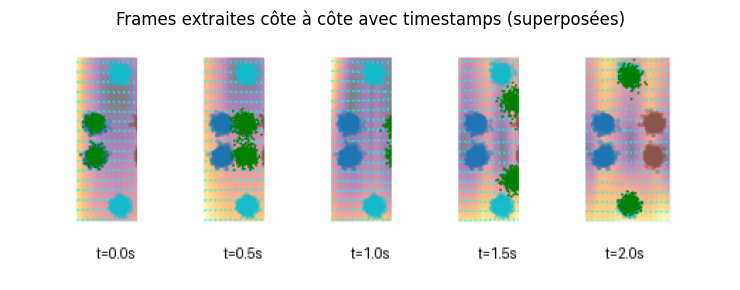

Image combinée créée avec timestamps et superposition


In [51]:
# Extraire les frames avec timestamps
frames = extract_frames_with_timestamps(video_path, timestamps)
print(f"Frames extraites: {len(frames)}")

# Créer l'image combinée avec les timestamps et superposition
combined_image = create_side_by_side_image(frames, 
                                         target_height=150,  # Ajustez la taille
                                         spacing=-60,  # Espacement négatif pour superposition
                                         add_labels=True,
                                         frame_numbers=[f"t={t:.1f}s" for t in timestamps])  # Labels avec timestamps

# Afficher l'image dans le notebook
plt.figure(figsize=(15, 3))
plt.imshow(combined_image)
plt.axis('off')
plt.title('Frames extraites côte à côte avec timestamps (superposées)')
plt.tight_layout()
plt.show()

print("Image combinée créée avec timestamps et superposition")

## Save Combined Image

Sauvegarde de l'image combinée pour utilisation dans l'article.

In [52]:
def save_combined_image(combined_image: Image.Image, 
                       output_path: str,
                       dpi: int = 300) -> None:
    """
    Sauvegarde l'image combinée en haute résolution pour l'article.
    
    Args:
        combined_image: Image PIL à sauvegarder
        output_path: Chemin de sortie
        dpi: Résolution en DPI
    """
    # Créer le dossier de sortie si nécessaire
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    # Sauvegarder en haute résolution
    combined_image.save(output_path, dpi=(dpi, dpi), quality=95)
    print(f"Image sauvegardée: {output_path}")
    print(f"Taille: {combined_image.size}, DPI: {dpi}")

# Exemple d'utilisation
output_folder = "article_images"
output_filename = "video_frames_comparison.png"
output_path = os.path.join(output_folder, output_filename)

# Sauvegarder (décommentez quand l'image est prête)
save_combined_image(combined_image, output_path, dpi=300)

print(f"Prêt à sauvegarder dans: {output_path}")

Image sauvegardée: article_images/video_frames_comparison.png
Taille: (510, 175), DPI: 300
Prêt à sauvegarder dans: article_images/video_frames_comparison.png


## Exemple Complet d'Utilisation

Voici un exemple complet qui combine toutes les étapes:

Fonctions définies. Exemples d'utilisation:

# Avec des numéros de frames:
# process_video_to_article_image('video.mp4', frame_numbers=[0, 25, 50, 75, 100])

# Avec des timestamps:
# process_video_to_article_image('video.mp4', timestamps=[0.0, 0.5, 1.0, 1.5, 2.0], use_timestamps=True)

# Aperçu rapide:
# quick_video_preview('video.mp4', num_frames=5)
Traitement de la vidéo: ../experiments_debug/test_properties_01_01/traj_bridges/traj_iter_1_tpairs_[0.0, 2.0]_direction_forward.mp4
Vidéo: 800x800, 41 frames
FPS: 20.00, Durée: 2.05s
Extraction aux timestamps: [0.0, 0.5, 1, 1.5, 2]
Frames extraites: 5
Frames extraites: 5


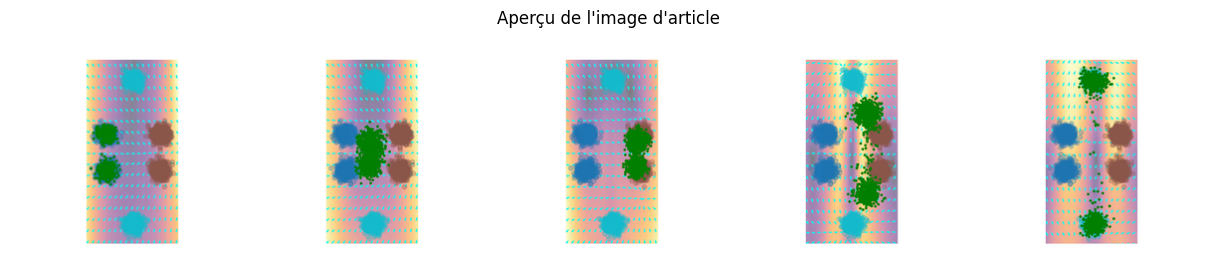

Image sauvegardée: article_images/trajectory_evolution.png
Taille: (1204, 240), DPI: 300


In [55]:
def process_video_to_article_image(video_path: str, 
                                 frame_numbers: List[int] = None,
                                 timestamps: List[float] = None,
                                 output_path: str = "article_images/output.png",
                                 target_height: int = 300,
                                 spacing: int = 1,  # Espacement très réduit
                                 use_timestamps: bool = False) -> None:
    """
    Pipeline complet pour créer une image d'article à partir d'une vidéo.
    
    Args:
        video_path: Chemin vers la vidéo
        frame_numbers: Liste des numéros de frames (si use_timestamps=False)
        timestamps: Liste des timestamps en secondes (si use_timestamps=True)
        output_path: Chemin de sortie de l'image
        target_height: Hauteur cible des frames
        spacing: Espacement minimal entre les frames
        use_timestamps: Si True, utilise les timestamps au lieu des numéros de frames
    """
    print(f"Traitement de la vidéo: {video_path}")
    
    # 1. Charger les informations vidéo
    video_info = load_video_info(video_path)
    print(f"Vidéo: {video_info['width']}x{video_info['height']}, {video_info['frame_count']} frames")
    print(f"FPS: {video_info['fps']:.2f}, Durée: {video_info['duration']:.2f}s")
    
    # 2. Extraire les frames
    if use_timestamps and timestamps:
        print(f"Extraction aux timestamps: {timestamps}")
        frames = extract_frames_with_timestamps(video_path, timestamps)
        labels = [f"t={t:.1f}s" for t in timestamps]
    elif frame_numbers:
        print(f"Extraction des frames: {frame_numbers}")
        frames = extract_frames_with_ffmpeg(video_path, frame_numbers)
        labels = [f"Frame {fn}" for fn in frame_numbers]
    else:
        raise ValueError("Veuillez spécifier soit frame_numbers soit timestamps")
    
    print(f"Frames extraites: {len(frames)}")
    
    if not frames:
        print("Aucune frame extraite avec succès!")
        return None
    
    # 3. Créer l'image combinée compacte
    combined_image = create_side_by_side_image(frames, 
                                             target_height=target_height,
                                             spacing=spacing,
                                             add_labels=False,  # Pas de labels pour plus de compacité
                                             frame_numbers=frame_numbers if not use_timestamps else None)
    
    # 4. Afficher dans le notebook avec des marges réduites
    plt.figure(figsize=(12, 3))  # Figure plus compacte
    plt.imshow(combined_image)
    plt.axis('off')
    plt.title('Aperçu de l\'image d\'article', fontsize=12)
    plt.tight_layout(pad=0.1)  # Marges très réduites
    plt.show()
    
    # 5. Sauvegarder
    save_combined_image(combined_image, output_path)
    
    return combined_image

def quick_video_preview(video_path: str, num_frames: int = 5) -> None:
    """
    Aperçu rapide d'une vidéo en extrayant des frames uniformément réparties.
    """
    try:
        video_info = load_video_info(video_path)
        total_frames = video_info['frame_count']
        
        # Répartir uniformément les frames
        if total_frames > num_frames:
            step = total_frames // num_frames
            frame_numbers = [i * step for i in range(num_frames)]
        else:
            frame_numbers = list(range(total_frames))
        
        print(f"Aperçu avec les frames: {frame_numbers}")
        
        frames = extract_frames_with_ffmpeg(video_path, frame_numbers)
        
        if frames:
            combined_image = create_side_by_side_image(frames, 
                                                     target_height=80,  # Plus petit pour l'aperçu
                                                     spacing=1,  # Espacement minimal
                                                     add_labels=False,  # Pas de labels
                                                     frame_numbers=frame_numbers)
            
            plt.figure(figsize=(10, 1.5))
            plt.imshow(combined_image)
            plt.axis('off')
            plt.title(f'Aperçu de {os.path.basename(video_path)}', fontsize=10)
            plt.tight_layout(pad=0.1)
            plt.show()
        
    except Exception as e:
        print(f"Erreur lors de l'aperçu: {e}")

# Exemple d'utilisation complète
print("Fonctions définies. Exemples d'utilisation:")
print()
print("# Avec des numéros de frames:")
print("# process_video_to_article_image('video.mp4', frame_numbers=[0, 25, 50, 75, 100])")
print()
print("# Avec des timestamps:")
print("# process_video_to_article_image('video.mp4', timestamps=[0.0, 0.5, 1.0, 1.5, 2.0], use_timestamps=True)")
print()
print("# Aperçu rapide:")
print("# quick_video_preview('video.mp4', num_frames=5)")

#Décommentez et modifiez selon vos besoins:
video_path = "../experiments_debug/test_properties_01_01/traj_bridges/traj_iter_1_tpairs_[0.0, 2.0]_direction_forward.mp4"
frame_numbers = [0, 25, 50, 75, 100]  # Frames à extraire
timestamps = [0.0, 0.5, 1, 1.5, 2]  # Ou timestamps en secondes
output_path = "article_images/trajectory_evolution.png"

# Option 1: Avec des numéros de frames
#result_image = process_video_to_article_image(video_path, frame_numbers=frame_numbers, output_path=output_path)

# Option 2: Avec des timestamps (version compacte)
result_image = process_video_to_article_image(video_path, timestamps=timestamps, output_path=output_path, 
                                            use_timestamps=True, target_height=240, spacing=1)

# Option 3: Aperçu rapide
# quick_video_preview(video_path)

Vidéo trouvée: ../experiments_debug/test_properties_01_01/traj_bridges/traj_iter_10_tpairs_[0.0, 2.0]_direction_forward.mp4
Informations vidéo iter_1: {'frame_count': 41, 'fps': 20.0, 'width': 800, 'height': 800, 'duration': 2.05}
Frames extraites pour iter_1: 4
Frames extraites pour iter_1: 4


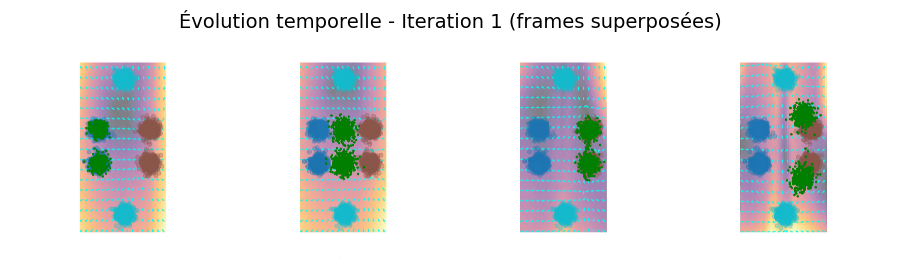

Image sauvegardée: article_images/trajectory_evolution_iter10.png
Taille: (39970, 10025), DPI: 300
Image iter_1 sauvegardée: article_images/trajectory_evolution_iter10.png


In [58]:
# Exemple avec une nouvelle vidéo (iter_1)
video_path_iter1 = "../experiments_debug/test_properties_01_01/traj_bridges/traj_iter_10_tpairs_[0.0, 2.0]_direction_forward.mp4"

# Vérifier que la vidéo existe
if os.path.exists(video_path_iter1):
    print(f"Vidéo trouvée: {video_path_iter1}")
    
    # Charger les informations de cette vidéo
    video_info_iter1 = load_video_info(video_path_iter1)
    print(f"Informations vidéo iter_1: {video_info_iter1}")
    
    # Timestamps pour l'extraction
    timestamps_iter1 = [0.0, 0.5, 1, 1.3]  # 6 frames réparties
    
    # Extraire les frames
    frames_iter1 = extract_frames_with_timestamps(video_path_iter1, timestamps_iter1)
    print(f"Frames extraites pour iter_1: {len(frames_iter1)}")
    
    if frames_iter1:
        # Créer l'image combinée très compacte
        combined_image_iter1 = create_side_by_side_image(frames_iter1, 
                                                       target_height=10000,  # Plus petit pour compacité
                                                       spacing=-10,  # Superposition importante
                                                       add_labels=True,
                                                       frame_numbers=[f"t={t:.1f}s" for t in timestamps_iter1])
        
        # Affichage
        plt.figure(figsize=(12, 2.5))
        plt.imshow(combined_image_iter1)
        plt.axis('off')
        plt.title('Évolution temporelle - Iteration 1 (frames superposées)', fontsize=14)
        plt.tight_layout(pad=0.1)
        plt.show()
        
        # Sauvegarder cette version
        output_path_iter1 = "article_images/trajectory_evolution_iter10.png"
        save_combined_image(combined_image_iter1, output_path_iter1, dpi=300)
        
        print(f"Image iter_1 sauvegardée: {output_path_iter1}")
    else:
        print("Aucune frame extraite pour iter_1")
        
else:
    print(f"Vidéo non trouvée: {video_path_iter1}")
    print("Vérifiez le chemin du fichier.")